# Anomalie-Detektion mit einem Convolutional Autoencoder

Hunde und Katzen sind jetzt beide normal. Wir trainieren einen Autoencoder mit ungestörten Bildern.
Danach prüfen wir, ob künstliches Rauschen und lokale Defekte den Rekonstruktionsfehler erhöhen.


# Vorbereitung

Die Zellen der Reihe nach ausführen. Der Download umfasst etwa 800 MB. Für das Training ist eine GPU empfehlenswert.


In [1]:
%pip install -q torch torchvision numpy matplotlib pillow kagglehub


Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

torch.manual_seed(42)
np.random.seed(42)
torch.set_num_threads(4)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Gerät:", device)

bildgroesse = 64
batchgroesse = 64
epochen = 30
rauschstaerke = 0.12  # Standardabweichung bei Pixelwerten zwischen 0 und 1
defektgroesse = 16    # Seitenlänge eines quadratischen Defekts in Pixeln


Gerät: cuda


# Cats-vs-Dogs automatisch herunterladen

Wir verwenden den öffentlichen [Cats-vs-Dogs-Datensatz auf Kaggle](https://www.kaggle.com/datasets/shaunthesheep/microsoft-catsvsdogs-dataset).
`kagglehub` lädt und entpackt ihn automatisch und verwendet bereits heruntergeladene Dateien erneut.
Für diesen öffentlichen Datensatz ist normalerweise keine Anmeldung nötig.


In [3]:
datenpfad = Path(kagglehub.dataset_download("shaunthesheep/microsoft-catsvsdogs-dataset"))
bildordner = next(datenpfad.rglob("PetImages"))
print("Bildordner:", bildordner)


Bildordner: /home/juebrauer/.cache/kagglehub/datasets/shaunthesheep/microsoft-catsvsdogs-dataset/versions/1/PetImages


# Bilder mit ImageFolder laden

`ImageFolder` liest die Unterordner `Cat` und `Dog`. Beschädigte Dateien werden übersprungen.
Wir verwenden den gesamten lesbaren Datensatz: 80 % zum Training, 10 % zur Kalibrierung und 10 % zum Test.
Die Tierart spielt für das Lernen keine Rolle.


In [4]:
def gueltiges_bild(pfad):
    if Path(pfad).suffix.lower() != ".jpg":
        return False
    try:
        with Image.open(pfad) as bild:
            bild.convert("RGB").load()
        return True
    except (OSError, ValueError):
        return False


transform = transforms.Compose([
    transforms.Resize((bildgroesse, bildgroesse)),
    transforms.ToTensor(),
])
daten = datasets.ImageFolder(bildordner, transform=transform, is_valid_file=gueltiges_bild)

anzahl_training = int(0.8 * len(daten))
anzahl_kalibrierung = int(0.1 * len(daten))
anzahl_test = len(daten) - anzahl_training - anzahl_kalibrierung
training, kalibrierung, test = random_split(
    daten,
    [anzahl_training, anzahl_kalibrierung, anzahl_test],
    generator=torch.Generator().manual_seed(42),
)

training_loader = DataLoader(training, batch_size=batchgroesse, shuffle=True)
kalibrierung_loader = DataLoader(kalibrierung, batch_size=batchgroesse)
test_loader = DataLoader(test, batch_size=batchgroesse)
print(f"Training: {len(training)}, Kalibrierung: {len(kalibrierung)}, Test: {len(test)}")
print("Klassen:", daten.classes)


/home/juebrauer/miniconda3/envs/env_teaching/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Training: 19998, Kalibrierung: 2499, Test: 2501
Klassen: ['Cat', 'Dog']


# Normale Beispielbilder


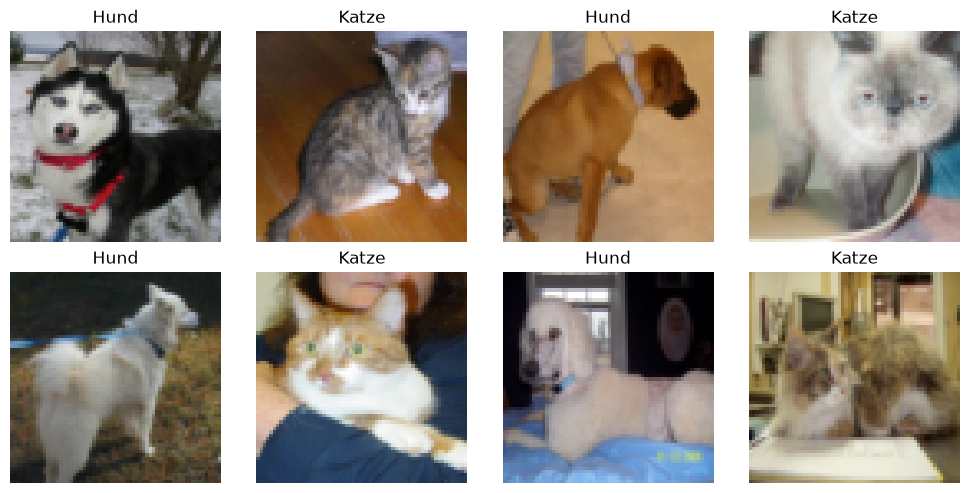

In [5]:
fig, achsen = plt.subplots(2, 4, figsize=(10, 5))
for i, achse in enumerate(achsen.flat):
    bild, klasse = training[i]
    achse.imshow(bild.permute(1, 2, 0))
    achse.set_title("Katze" if daten.classes[klasse] == "Cat" else "Hund")
    achse.axis("off")
plt.tight_layout()
plt.show()


# Ein größerer Convolutional Autoencoder

Der Encoder verkleinert die räumliche Auflösung auf 8 × 8 statt auf 4 × 4 Pixel.
64 Merkmalskanäle behalten mehr Bildinformation. Der Decoder vergrößert das Bild und verfeinert es mit einer weiteren Faltung.
Es gibt keine direkte Verbindung vom Eingabebild zum Ausgang.


In [6]:
class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=4, stride=2, padding=1),   # 64 -> 32 Pixel
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),  # 32 -> 16 Pixel
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=4, stride=2, padding=1),  # 16 -> 8 Pixel
            nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 3, kernel_size=3, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


modell = Autoencoder().to(device)
verlustfunktion = nn.MSELoss()
optimierer = torch.optim.Adam(modell.parameters(), lr=0.001)


# Mit normalen Hunde- und Katzenbildern trainieren

Eingabe und Ziel sind dasselbe ungestörte Bild. Die Klassenlabels werden ignoriert.
Wir minimieren den mittleren quadratischen Fehler (MSE) und verringern nach der Hälfte der Epochen die Lernrate.


Epoche  1/30: MSE = 0.01538
Epoche  2/30: MSE = 0.00595
Epoche  3/30: MSE = 0.00420
Epoche  4/30: MSE = 0.00363
Epoche  5/30: MSE = 0.00296
Epoche  6/30: MSE = 0.00244
Epoche  7/30: MSE = 0.00225
Epoche  8/30: MSE = 0.00203
Epoche  9/30: MSE = 0.00196
Epoche 10/30: MSE = 0.00180
Epoche 11/30: MSE = 0.00175
Epoche 12/30: MSE = 0.00164
Epoche 13/30: MSE = 0.00157
Epoche 14/30: MSE = 0.00157
Epoche 15/30: MSE = 0.00147
Epoche 16/30: MSE = 0.00130
Epoche 17/30: MSE = 0.00127
Epoche 18/30: MSE = 0.00125
Epoche 19/30: MSE = 0.00122
Epoche 20/30: MSE = 0.00121
Epoche 21/30: MSE = 0.00119
Epoche 22/30: MSE = 0.00117
Epoche 23/30: MSE = 0.00115
Epoche 24/30: MSE = 0.00113
Epoche 25/30: MSE = 0.00111
Epoche 26/30: MSE = 0.00110
Epoche 27/30: MSE = 0.00108
Epoche 28/30: MSE = 0.00106
Epoche 29/30: MSE = 0.00105
Epoche 30/30: MSE = 0.00103


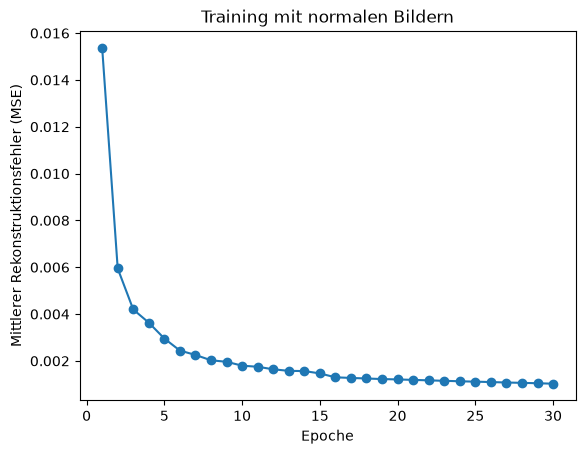

In [7]:
trainingsfehler = []

for epoche in range(epochen):
    if epoche == epochen // 2:
        optimierer.param_groups[0]["lr"] = 0.0003

    modell.train()
    fehlersumme = 0.0
    for bilder, _ in training_loader:
        bilder = bilder.to(device)
        optimierer.zero_grad()
        rekonstruktionen = modell(bilder)
        verlust = verlustfunktion(rekonstruktionen, bilder)
        verlust.backward()
        optimierer.step()
        fehlersumme += verlust.item() * len(bilder)

    mittlerer_fehler = fehlersumme / len(training)
    trainingsfehler.append(mittlerer_fehler)
    print(f"Epoche {epoche + 1:2d}/{epochen}: MSE = {mittlerer_fehler:.5f}")

plt.plot(range(1, epochen + 1), trainingsfehler, marker="o")
plt.xlabel("Epoche")
plt.ylabel("Mittlerer Rekonstruktionsfehler (MSE)")
plt.title("Training mit normalen Bildern")
plt.show()


# Schwellenwert aus normalen Bildern bestimmen

Der Fehler wird pro Bild über alle Pixel und Farbkanäle gemittelt.
Der Median der Kalibrierungsfehler beschreibt einen typischen Fehler; ihr 95-%-Quantil ist unser Schwellenwert.
Größere Fehler gelten als Anomalie. Testbilder und Störungen beeinflussen den Schwellenwert nicht.


In [8]:
def fehler_pro_bild(bilder, rekonstruktionen):
    return ((bilder - rekonstruktionen) ** 2).mean(dim=(1, 2, 3))


modell.eval()
kalibrierungsfehler = []
with torch.no_grad():
    for bilder, _ in kalibrierung_loader:
        bilder = bilder.to(device)
        fehler = fehler_pro_bild(bilder, modell(bilder))
        kalibrierungsfehler.extend(fehler.cpu().numpy())

schwellenwert = np.quantile(kalibrierungsfehler, 0.95)
print(f"Typischer normaler Fehler (Median): {np.median(kalibrierungsfehler):.5f}")
print(f"Schwellenwert (95-%-Quantil):        {schwellenwert:.5f}")


Typischer normaler Fehler (Median): 0.00091
Schwellenwert (95-%-Quantil):        0.00217


# Künstliche Anomalien erzeugen

Wir addieren leichtes gaußsches Rauschen oder ersetzen ein kleines Quadrat durch zufällige Pixel.
Der lokale Defekt belegt 6,25 % der Bildfläche. Beide Störungen entstehen erst im Test; trainiert wird ausschließlich mit normalen Bildern.


In [9]:
def mit_rauschen(bilder, generator):
    rauschen = torch.randn(bilder.shape, generator=generator)
    return (bilder + rauschstaerke * rauschen).clamp(0, 1)


def mit_defekt(bilder, generator):
    gestoert = bilder.clone()  # Die Originalbilder unverändert lassen
    for bild in gestoert:
        oben = torch.randint(0, bildgroesse - defektgroesse + 1, (1,), generator=generator).item()
        links = torch.randint(0, bildgroesse - defektgroesse + 1, (1,), generator=generator).item()
        bild[:, oben:oben + defektgroesse, links:links + defektgroesse] = torch.rand(
            (3, defektgroesse, defektgroesse), generator=generator
        )
    return gestoert


# Rekonstruktionsfehler im Test vergleichen

Jedes Testbild wird normal, verrauscht und mit Defekt ausgewertet.
Wir vergleichen immer die jeweilige Eingabe mit ihrer Rekonstruktion, auch bei gestörten Bildern.
Das saubere Original wird für die Anomalieentscheidung nicht benötigt.


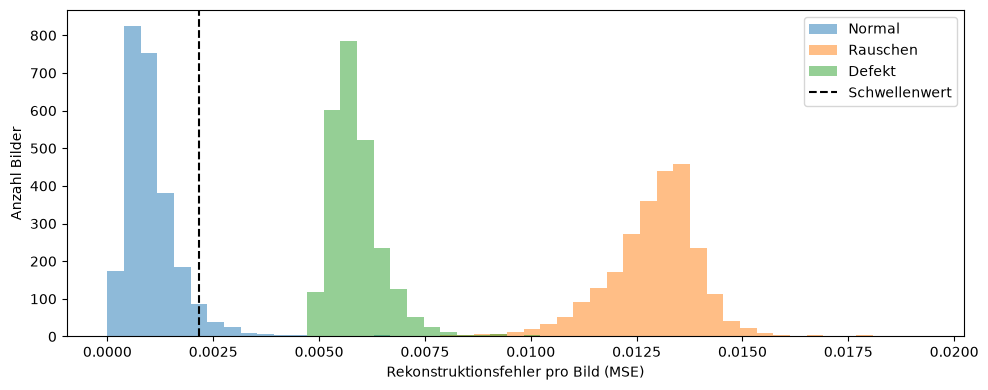

Bildtyp        Median-MSE    Als Anomalie erkannt
Normal            0.00088                   5.2%
Rauschen          0.01306                 100.0%
Defekt            0.00576                 100.0%

Normale Bilder korrekt erkannt: 94.8%
Fehlalarmrate: 5.2%


In [10]:
testfehler = {"Normal": [], "Rauschen": [], "Defekt": []}
generator = torch.Generator().manual_seed(123)
modell.eval()

with torch.no_grad():
    for bilder, _ in test_loader:
        varianten = {
            "Normal": bilder,
            "Rauschen": mit_rauschen(bilder, generator),
            "Defekt": mit_defekt(bilder, generator),
        }
        for name, eingabe in varianten.items():
            eingabe = eingabe.to(device)
            fehler = fehler_pro_bild(eingabe, modell(eingabe))
            testfehler[name].extend(fehler.cpu().numpy())

testfehler = {name: np.array(werte) for name, werte in testfehler.items()}

grenzen = np.linspace(0, max(werte.max() for werte in testfehler.values()), 50)
plt.figure(figsize=(10, 4))
for name, werte in testfehler.items():
    plt.hist(werte, bins=grenzen, alpha=0.5, label=name)
plt.axvline(schwellenwert, color="black", linestyle="--", label="Schwellenwert")
plt.xlabel("Rekonstruktionsfehler pro Bild (MSE)")
plt.ylabel("Anzahl Bilder")
plt.legend()
plt.tight_layout()
plt.show()

print(f"{'Bildtyp':<12} {'Median-MSE':>12} {'Als Anomalie erkannt':>23}")
for name, werte in testfehler.items():
    print(f"{name:<12} {np.median(werte):>12.5f} {(werte > schwellenwert).mean():>22.1%}")

fehlalarmrate = (testfehler["Normal"] > schwellenwert).mean()
print(f"\nNormale Bilder korrekt erkannt: {1 - fehlalarmrate:.1%}")
print(f"Fehlalarmrate: {fehlalarmrate:.1%}")


# Originale und Rekonstruktionen ansehen

Wir zeigen die ersten vier Testbilder und beide Störungen, unabhängig von den Entscheidungen.
Vergleiche die Bilddetails und die Rekonstruktionsfehler. Die drei Varianten verwenden jeweils dasselbe Ausgangsbild.


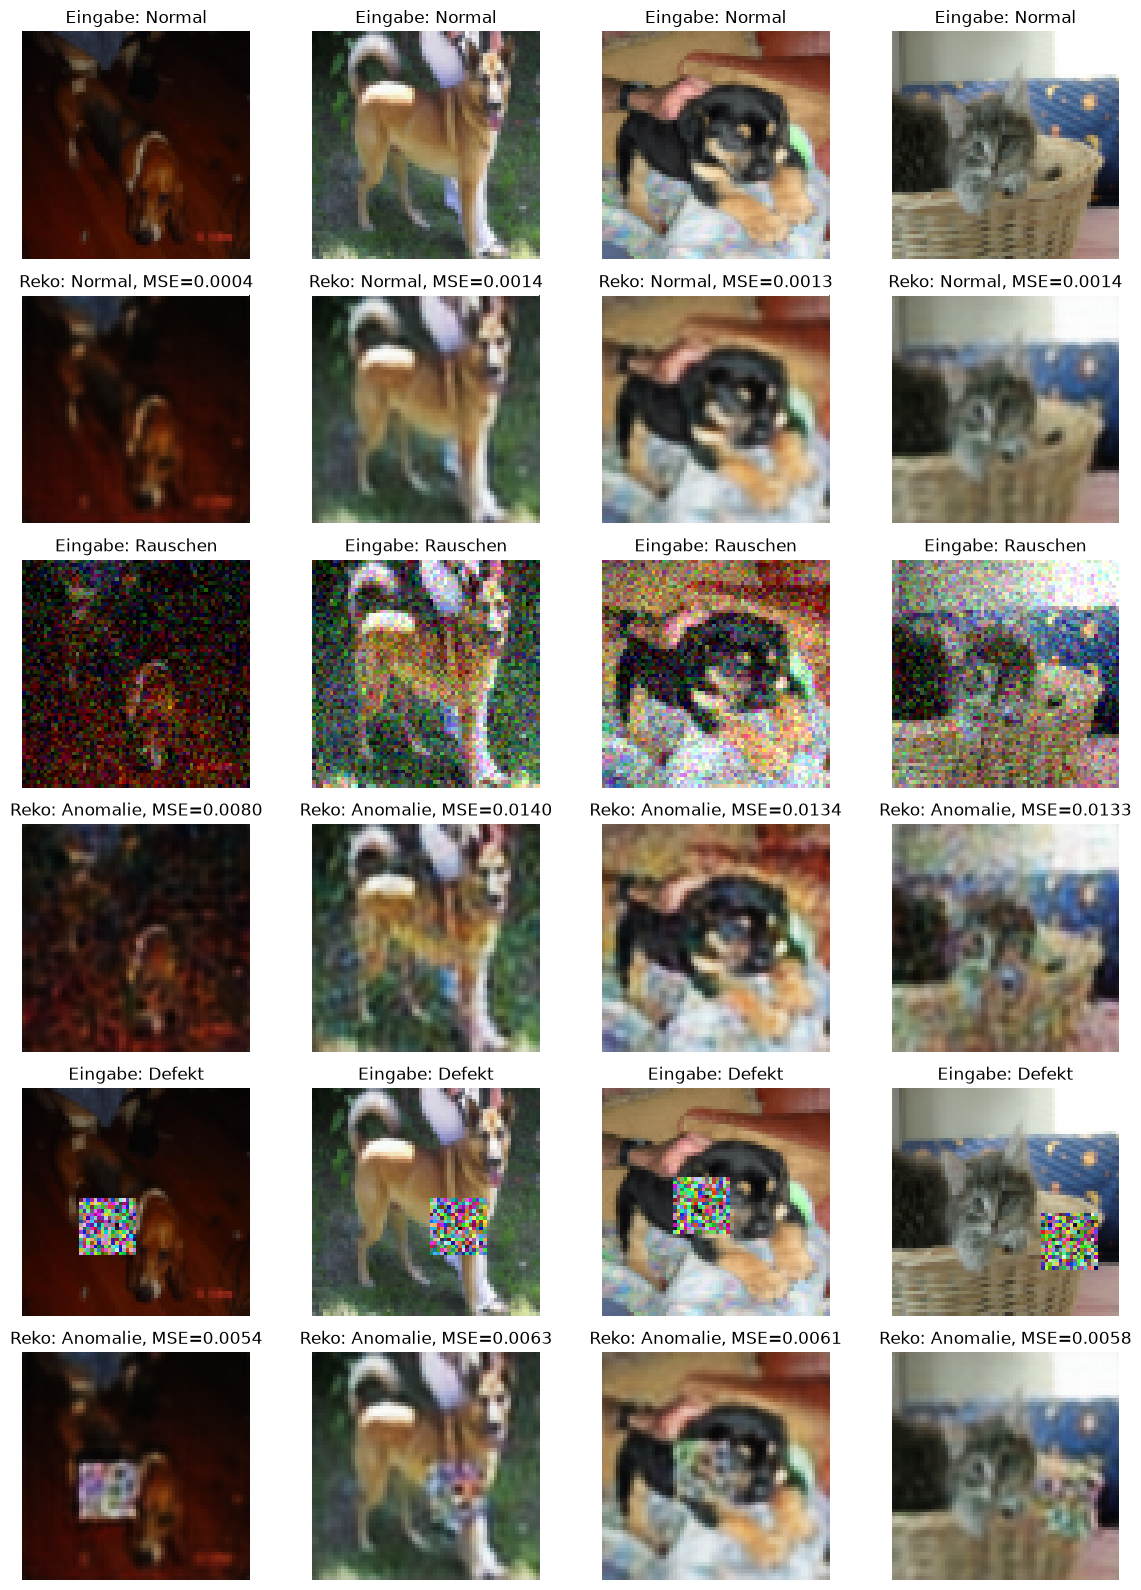

In [11]:
beispiele = torch.stack([test[i][0] for i in range(4)])
generator = torch.Generator().manual_seed(456)
varianten = {
    "Normal": beispiele,
    "Rauschen": mit_rauschen(beispiele, generator),
    "Defekt": mit_defekt(beispiele, generator),
}

fig, achsen = plt.subplots(6, 4, figsize=(12, 16))
modell.eval()
with torch.no_grad():
    for gruppe, (name, eingaben) in enumerate(varianten.items()):
        rekonstruktionen = modell(eingaben.to(device)).cpu()
        fehler = fehler_pro_bild(eingaben, rekonstruktionen).numpy()
        for i in range(4):
            achsen[2 * gruppe, i].imshow(eingaben[i].permute(1, 2, 0))
            achsen[2 * gruppe, i].set_title(f"Eingabe: {name}")
            entscheidung = "Anomalie" if fehler[i] > schwellenwert else "Normal"
            achsen[2 * gruppe + 1, i].imshow(rekonstruktionen[i].permute(1, 2, 0))
            achsen[2 * gruppe + 1, i].set_title(f"Reko: {entscheidung}, MSE={fehler[i]:.4f}")
for achse in achsen.flat:
    achse.axis("off")
plt.tight_layout()
plt.show()


# Was lernen wir daraus?

Der Autoencoder soll normale Bildstrukturen rekonstruieren. Zufällige Störungen sind schwerer zu rekonstruieren und können dadurch den Fehler erhöhen.
Die Tabelle zeigt, ob das auf den getrennten Testdaten gelingt. Bei normalen Bildern zählt die Rate als Fehlalarm, bei Störungen als Erkennungsrate.

Ein größerer latenter Raum verbessert die Bilddetails. Ein zu mächtiger Autoencoder kann aber auch Anomalien rekonstruieren.
Ein kleiner Defekt kann im Mittel über das ganze Bild untergehen; leichte Störungen bleiben deshalb schwieriger zu erkennen.
Die Ergebnisse für künstliches Rauschen gelten nicht automatisch auch für reale Defekte.
